# Улучшение baseline-модели прогнозирования стоимости недвижимости

Проект продолжает задачу Яндекс Недвижимости: по характеристикам квартиры и дома предсказываем price. Работаем с очищенным датасетом flats_buildings_clean из прошлой дисциплины, в нём 123 525 объектов.

Яндекс Недвижимость - маркетплейс для аренды и покупки жилья. В прошлом проекте была сделана базовая модель оценки рыночной стоимости квартиры. Задача текущего проекта заключается в улучшении основной метрики проекта, которая влияет на точность предсказаний стоимости недвижимости и, как следствие, на количество успешных сделок на маркетплейсе. Помимо этого процесс улучшения необходимо сделать воспроизводимым: все эксперименты логируются в MLflow, модели регистрируются в Model Registry, изменения фиксируются набором метрик и артефактов. С точки зрения машинного обучения это по-прежнему задача регрессии.

## 0. Настройка окружения и воспроизводимое разбиение

Перед запусков выполняем `python mlflow_server/register_baseline.py` (подробнее см. README).
Ноутбук использует то же разбиение train/test, что и baseline: 80%/20%, `random_state=42`.
Отбор признаков и подбор гиперпараметров выполняются только на train; test используется для итоговой оценки каждой версии.

In [ ]:
import json
import os
import sys
import time
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import mlflow
import mlflow.sklearn
import numpy as np
import optuna
import pandas as pd
import seaborn as sns
from autofeat import AutoFeatRegressor
from dotenv import load_dotenv
from mlflow.models.signature import infer_signature
from mlxtend.feature_selection import SequentialFeatureSelector
from optuna.integration import MLflowCallback
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import KFold, RandomizedSearchCV, cross_val_score
from sklearn.pipeline import FeatureUnion, Pipeline
from sklearn.preprocessing import KBinsDiscretizer, OneHotEncoder, PolynomialFeatures

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "model_improvement" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))
from model_improvement.utils import (
    ARTIFACTS_DIR, CATEGORICAL_COLS, load_data, log_environment,
    regression_metrics, save_json, split_data,
)

load_dotenv(PROJECT_ROOT / ".env")
load_dotenv(PROJECT_ROOT / "local-emulation.env")
ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)
warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

RANDOM_STATE = int(os.getenv("RANDOM_STATE", "42"))
FAST_RUN = os.getenv("FAST_RUN", "false").lower() == "true"
N_TRIALS = 3 if FAST_RUN else 20
N_ITER = 3 if FAST_RUN else 15
CANDIDATE_COUNT = 12 if FAST_RUN else 25
SELECTED_COUNT = 6 if FAST_RUN else 10
SELECTION_SAMPLE_SIZE = 2_000 if FAST_RUN else 5_000
SEARCH_SAMPLE_SIZE = 10_000 if FAST_RUN else 25_000
N_ESTIMATORS = 30 if FAST_RUN else 100

tracking_uri = os.getenv("MLFLOW_TRACKING_URI", f"sqlite:///{PROJECT_ROOT / 'mlflow.db'}")
mlflow.set_tracking_uri(tracking_uri)
EXPERIMENT_NAME = os.getenv("MLFLOW_EXPERIMENT_NAME", "real_estate_price_improvement")
MODEL_NAME = os.getenv("MLFLOW_MODEL_NAME", "real_estate_price_model")
experiment = mlflow.set_experiment(EXPERIMENT_NAME)
NOTEBOOK_PATH = PROJECT_ROOT / "model_improvement" / "model_improvement.ipynb"

print(f"MLflow: {mlflow.get_tracking_uri()}")
print(f"Experiment: {EXPERIMENT_NAME}, id={experiment.experiment_id}")
print(f"FAST_RUN={FAST_RUN}; trials={N_TRIALS}; random search iterations={N_ITER}")

c:\Users\Natrogona\Documents\Магистратура\MlOps_baseline_project\MlOps_baseline\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


MLflow: http://127.0.0.1:5000
Experiment: real_estate_price_improvement, id=1
FAST_RUN=False; trials=20; random search iterations=15


In [ ]:
data_path = PROJECT_ROOT / os.getenv("DATA_PATH", "data/initial_data.csv")
df = load_data(data_path)
X_train, X_test, y_train, y_test = split_data(df, random_state=RANDOM_STATE)

baseline_path = PROJECT_ROOT / os.getenv("BASELINE_MODEL_PATH", "baseline/model.pkl")
baseline_model = joblib.load(baseline_path)
baseline_predictions = baseline_model.predict(X_test)
baseline_metrics = regression_metrics(y_test, baseline_predictions)

print(f"Всего строк: {len(df):,}; train: {len(X_train):,}; test: {len(X_test):,}")
print("Baseline:", json.dumps(baseline_metrics, ensure_ascii=False, indent=2))
assert list(X_train.columns) == list(X_test.columns)
assert not X_train.index.intersection(X_test.index).any()

Всего строк: 123,525; train: 98,820; test: 24,705
Baseline: {
  "mae": 2003737.1546692452,
  "rmse": 2721365.778902152,
  "r2": 0.7749163851066123
}


## Этап 1. MLflow Tracking Server и Model Registry

MLflow поднимаем отдельно от ноутбука через shell-скрипт mlflow_server/run_mlflow.sh. PostgreSQL используем для хранения экспериментов, метрик и Model Registry, а S3 для моделей, графиков, ноутбуков и других артефактов.

После запуска сервиса выполняем mlflow_server/register_baseline.py. Скрипт заново считает метрики baseline на той же тестовой выборке, сохраняет параметры модели, сигнатуру, окружение и код, после чего регистрирует первую версию модели в Model Registry.

Ноутбук подключается к уже созданному эксперименту, поэтому EDA и все следующие версии модели попадают в тот же MLflow и остаются там рядом с baseline.

## Этап 2. Исследовательский анализ данных (EDA)

### 2.1. Структура, типы и качество данных

Данные уже были очищены Airflow-пайплайном в рамках предыдущего проекта. Здесь дополнительно проверим датасет на дубли, пропуски, типы и диапазоны, но не удаляем строки по test-признакам и не меняем выборку.

In [ ]:
# Общий обзор: размер, типы, пропуски, дубли и описательные статистики.
print("Размер датасета:", df.shape)
display(df.head())
display(df.dtypes.rename("dtype").to_frame())
missing = df.isna().sum().rename("missing").to_frame()
missing["missing_pct"] = 100 * missing["missing"] / len(df)
display(missing)
print("Дубли id:", int(df["id"].duplicated().sum()))
print("Полные дубли строк:", int(df.duplicated().sum()))
display(df.describe().T)

quality_summary = {
    "rows": len(df), "columns": len(df.columns),
    "missing_cells": int(df.isna().sum().sum()),
    "duplicate_ids": int(df["id"].duplicated().sum()),
    "feature_count": X_train.shape[1],
}
save_json(quality_summary, ARTIFACTS_DIR / "eda_quality.json")

Размер датасета: (123525, 18)


,id,building_id,floor,kitchen_area,living_area,rooms,is_apartment,studio,total_area,price,build_year,building_type_int,latitude,longitude,ceiling_height,flats_count,floors_total,has_elevator
0,0,6220,9,9.9,19.900000,1,0,0,35.099998,9500000,1965,6,55.717113,37.781120,2.64,84,12,1
1,1,18012,7,8.5,16.600000,1,0,0,43.000000,13500000,2001,2,55.794849,37.608013,3.00,97,10,1
2,2,17821,9,9.0,32.000000,2,0,0,56.000000,13500000,2000,4,55.740040,37.761742,2.70,80,10,1
3,3,18579,1,10.1,43.099998,3,0,0,76.000000,20000000,2002,4,55.672016,37.570877,2.64,771,17,1
4,4,9293,3,3.0,14.000000,1,0,0,24.000000,5200000,1971,1,55.808807,37.707306,2.60,208,9,1


,dtype
id,int64
building_id,int64
floor,int64
kitchen_area,float64
living_area,float64
rooms,int64
is_apartment,int32
studio,int32
total_area,float64
price,int64


,missing,missing_pct
id,0,0.0
building_id,0,0.0
floor,0,0.0
kitchen_area,0,0.0
living_area,0,0.0
rooms,0,0.0
is_apartment,0,0.0
studio,0,0.0
total_area,0,0.0
price,0,0.0


Дубли id: 0
Полные дубли строк: 0


,count,mean,std,min,25%,50%,75%,max
id,123525.0,7.008759e+04,4.104925e+04,0.000000e+00,3.432200e+04,7.026400e+04,1.052860e+05,1.413610e+05
building_id,123525.0,1.377163e+04,6.646489e+03,4.000000e+00,8.522000e+03,1.365200e+04,1.963500e+04,2.462000e+04
floor,123525.0,7.264829e+00,5.323996e+00,1.000000e+00,3.000000e+00,6.000000e+00,1.000000e+01,5.500000e+01
kitchen_area,123525.0,9.052734e+00,3.035239e+00,1.500000e+00,7.000000e+00,8.900000e+00,1.000000e+01,1.020000e+02
living_area,123525.0,3.130897e+01,1.185419e+01,2.000000e+00,2.000000e+01,3.040000e+01,4.000000e+01,1.073000e+02
rooms,123525.0,1.962720e+00,8.166056e-01,1.000000e+00,1.000000e+00,2.000000e+00,3.000000e+00,6.000000e+00
is_apartment,123525.0,9.026513e-03,9.457858e-02,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00
studio,123525.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
total_area,123525.0,5.287768e+01,1.682187e+01,1.280000e+01,3.880000e+01,5.040000e+01,6.300000e+01,1.040000e+02
price,123525.0,1.247813e+07,5.681144e+06,3.390000e+06,8.600000e+06,1.100000e+07,1.450000e+07,4.450000e+07


По датасету: пропусков и дублей нет, типы данных выглядят нормально. 
Отдельная проверка здесь может казаться излишней, но не хотелось для чистоты эксперимента на всякий случай проверим еще раз. 

### 2.2. Распределение целевой переменной и основных числовых признаков

Логарифм цены показываем только для анализа: модель обучается на исходной цене, поэтому метрики
остаются в рублях и напрямую сравнимы с baseline.

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
sns.histplot(df["price"] / 1e6, bins=50, ax=axes[0, 0])
axes[0, 0].set(title="Распределение цены", xlabel="Цена, млн руб.")
sns.histplot(np.log1p(df["price"]), bins=50, ax=axes[0, 1])
axes[0, 1].set(title="Распределение log1p(price)", xlabel="log1p(price)")
sns.histplot(df["total_area"], bins=50, ax=axes[1, 0])
axes[1, 0].set(title="Общая площадь", xlabel="м²")
sns.histplot(df["rooms"], bins=np.arange(0.5, df["rooms"].max() + 1.5, 1), ax=axes[1, 1])
axes[1, 1].set(title="Количество комнат", xlabel="комнаты")
plt.tight_layout()
fig.savefig(ARTIFACTS_DIR / "eda_distributions.png", dpi=150, bbox_inches="tight")
plt.show()

<Figure size 1500x1000 with 4 Axes>

Цена сильно скошена вправо. Поэтому нельзя смотреть только на MAE: на дорогих квартирах крупные ошибки будут сильно портить RMSE.

### 2.3. Корреляции и взаимодействие признаков с ценой

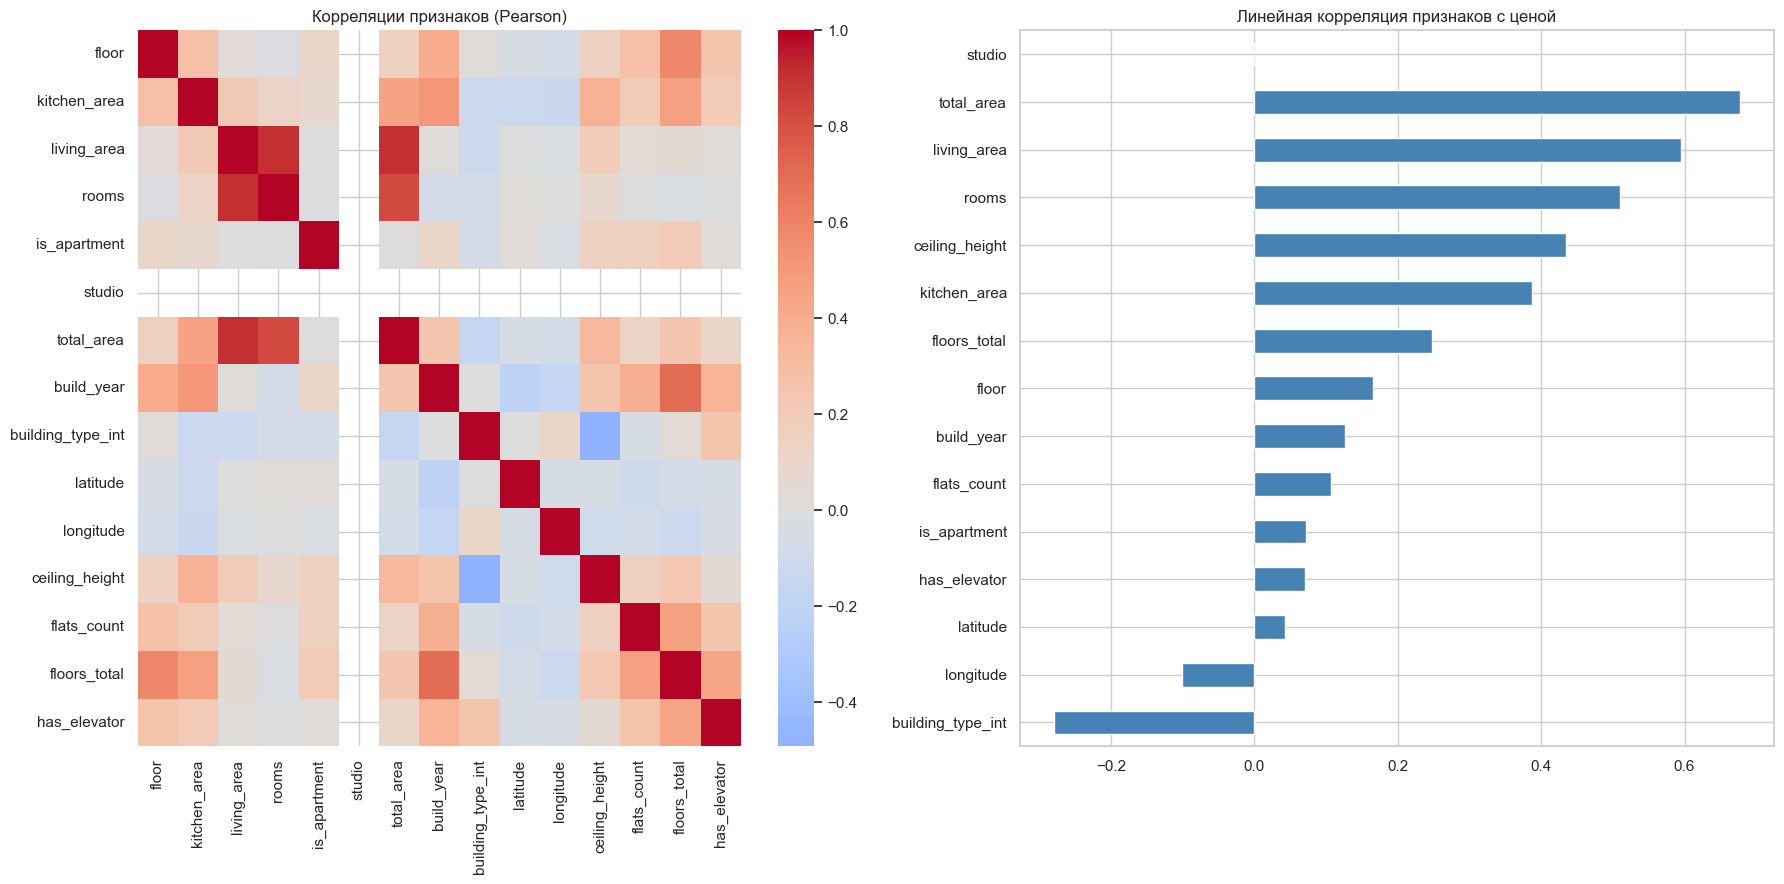

,pearson_with_price,spearman_with_price
building_type_int,-0.278748,-0.235391
longitude,-0.100818,-0.135994
latitude,0.042656,0.045712
has_elevator,0.070400,0.078137
is_apartment,0.072567,0.056220
flats_count,0.106452,0.074919
build_year,0.126064,0.136102
floor,0.166090,0.140028
floors_total,0.248224,0.203972
kitchen_area,0.386743,0.372044


In [ ]:
numeric_with_target = numeric_for_eda.join(df[["price"]])

pearson_with_price = numeric_with_target.corr(numeric_only=True)["price"].drop("price")
spearman_with_price = numeric_with_target.corr(method="spearman", numeric_only=True)["price"].drop("price")

fig, axes = plt.subplots(1, 2, figsize=(18, 9))

sns.heatmap(pearson, cmap="coolwarm", center=0, ax=axes[0])
axes[0].set_title("Корреляции признаков (Pearson)")

pearson_with_price.sort_values().plot.barh(ax=axes[1], color="steelblue")
axes[1].set_title("Линейная корреляция признаков с ценой")

plt.tight_layout()
fig.savefig(ARTIFACTS_DIR / "eda_correlations.png", dpi=150, bbox_inches="tight")
plt.show()

display(
    pd.DataFrame({
        "pearson_with_price": pearson_with_price,
        "spearman_with_price": spearman_with_price,
    }).sort_values("pearson_with_price")
)

По результатам расчета корреляционной матрицы самый сильный сигнал идёт от площади: total_area имеет корреляцию с ценой 0,677, дальше идут living_area 0,595 и rooms 0,511. Также заметную связь показывают ceiling_height 0,434 и kitchen_area 0,387.

По Спирмену результаты похожие, но rooms становится сильнее, чем по Пирсону: 0,583 против 0,511. Это говорит о том, что зависимость есть, но она не идеально линейная.

building_type_int имеет отрицательную корреляцию около -0,28, но это не обычное число, а код категории. Поэтому говорить о линейной зависимости здесь нельзя, для модели этот признак лучше закодировать (попробуем через OneHotEncoder).

Географические координаты сами по себе показывают слабую линейную связь: latitude около 0,04, longitude около -0,10. Значит, для географии имеет смысл пробовать не линейную корреляцию, а биннинг и нелинейные признаки.

2026-11-21 19:37:13,839 INFO: Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2026-11-21 19:37:13,875 INFO: Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


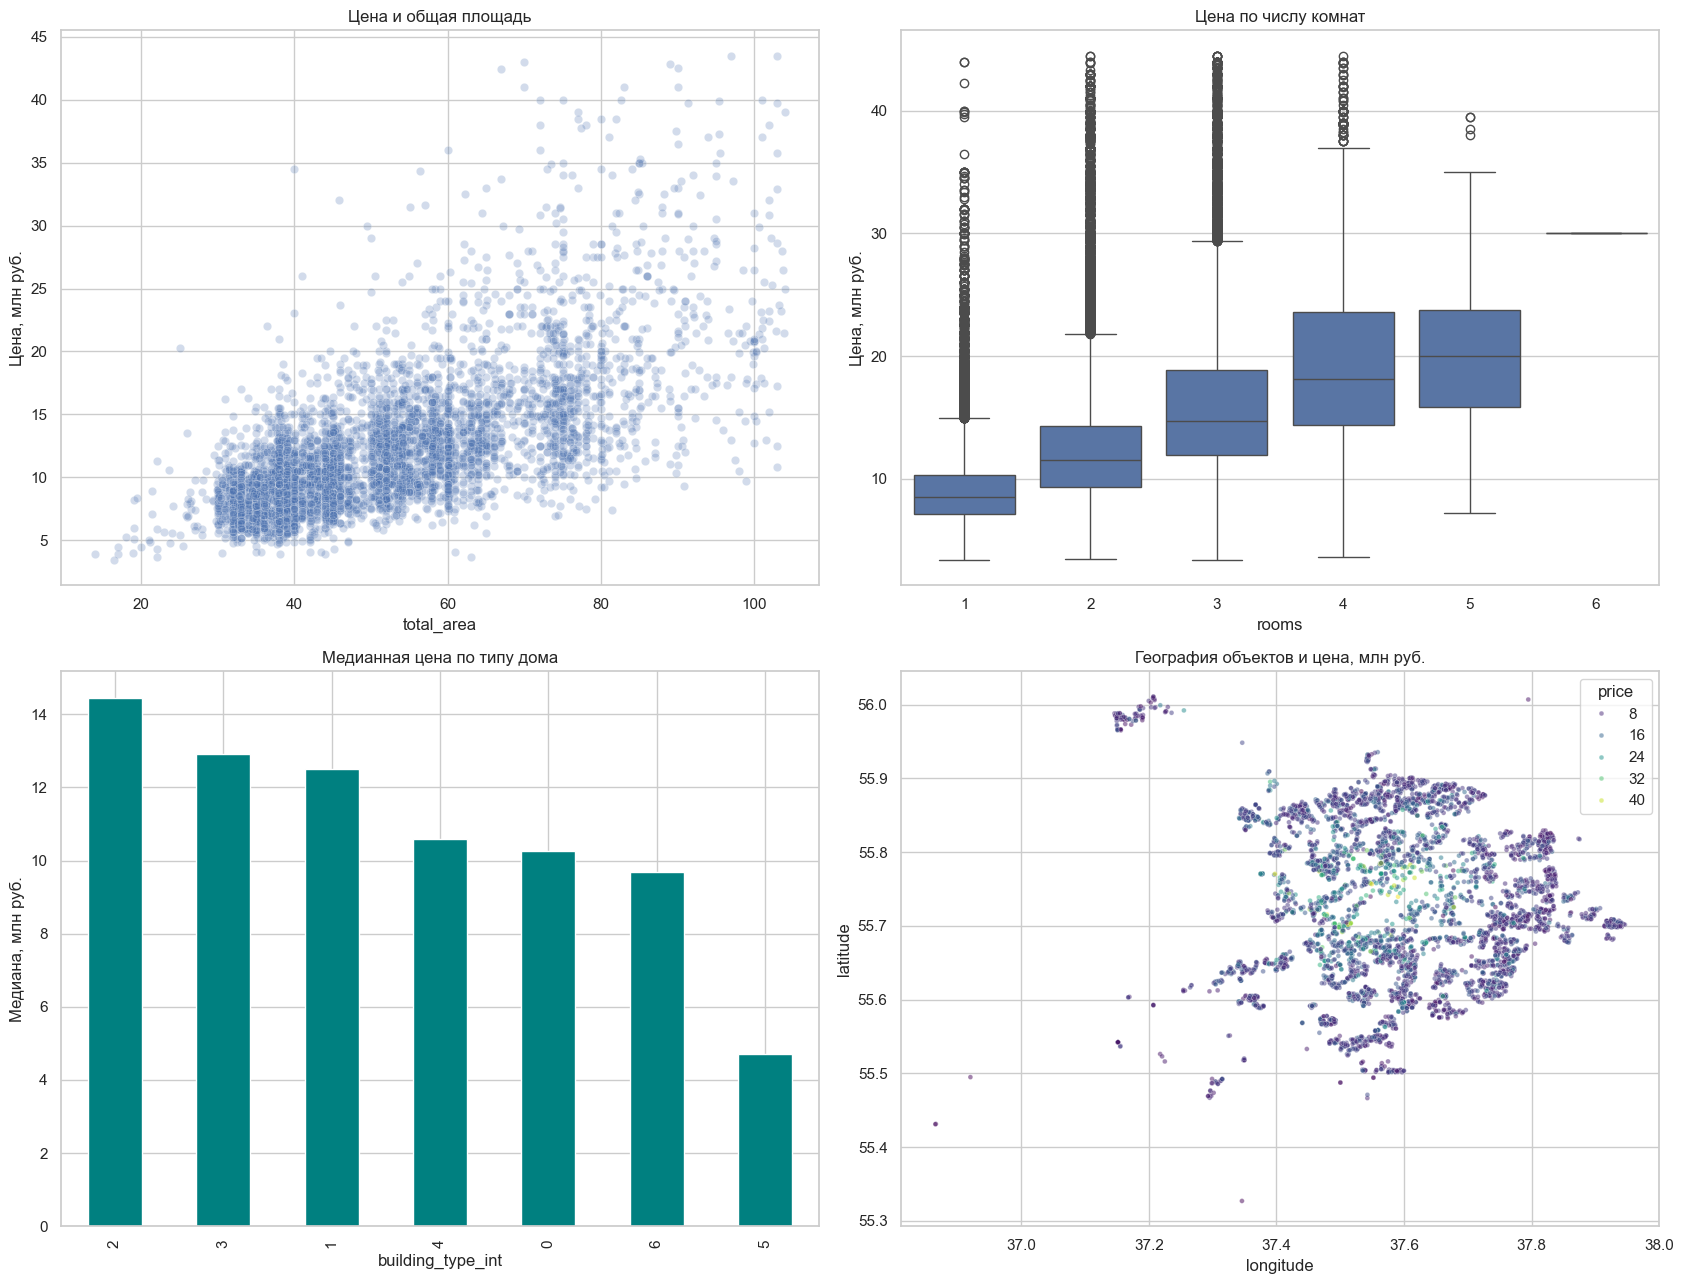

In [ ]:
# Проверяем форму зависимости цены от площади, комнат, типа дома и географии.
plot_sample = df.sample(min(5_000, len(df)), random_state=RANDOM_STATE)
fig, axes = plt.subplots(2, 2, figsize=(17, 13))
sns.scatterplot(data=plot_sample, x="total_area", y=plot_sample["price"] / 1e6, alpha=0.25, ax=axes[0, 0])
axes[0, 0].set(title="Цена и общая площадь", ylabel="Цена, млн руб.")
sns.boxplot(data=df, x="rooms", y=df["price"] / 1e6, ax=axes[0, 1])
axes[0, 1].set(title="Цена по числу комнат", ylabel="Цена, млн руб.")
median_by_type = df.groupby("building_type_int")["price"].median().sort_values(ascending=False) / 1e6
median_by_type.plot.bar(ax=axes[1, 0], color="teal")
axes[1, 0].set(title="Медианная цена по типу дома", xlabel="building_type_int", ylabel="Медиана, млн руб.")
sns.scatterplot(data=plot_sample, x="longitude", y="latitude", hue=plot_sample["price"] / 1e6,
                palette="viridis", alpha=0.5, s=12, ax=axes[1, 1])
axes[1, 1].set_title("География объектов и цена, млн руб.")
plt.tight_layout()
fig.savefig(ARTIFACTS_DIR / "eda_target_relations.png", dpi=150, bbox_inches="tight")
plt.show()

Здесь хорошо видно, что цена растёт вместе с общей площадью, но зависимость не строгая. Особенно широкий разброс начинается примерно после 60 кв.м: похожие по площади квартиры могут стоить заметно по-разному. Значит, одной площади недостаточно, нужны дополнительные признаки и нелинейная модель.

С числом комнат картина похожая. Медианная цена растёт от однокомнатных к четырёхкомнатным, но дальше разница уже не такая однозначная. При этом разброс внутри каждой группы большой, особенно у квартир с тремя и четырьмя комнатами.

По типу дома разница в медианной цене очень заметная. Например, типы 2, 3 и 4 в среднем дороже, а тип 5 заметно дешевле. Это подтверждает, что building_type_int нельзя игнорировать, но работать с ним нужно как с категорией.

География тоже влияет, но не как простая линейная зависимость. На scatterplot видны отдельные скопления и районы с разной ценовой структурой. Поэтому координаты имеет смысл не просто подавать в модель как есть, а дополнительно разбивать на интервалы и пробовать нелинейные признаки.

Продублируем результат в числовом представлении. 

In [ ]:
eda_statistics = {
    "price_mean": float(df["price"].mean()),
    "price_median": float(df["price"].median()),
    "price_skew": float(df["price"].skew()),
    "total_area_pearson": float(df["total_area"].corr(df["price"])),
    "living_area_pearson": float(df["living_area"].corr(df["price"])),
    "rooms_pearson": float(df["rooms"].corr(df["price"])),
    "building_type_pearson": float(df["building_type_int"].corr(df["price"])),
}
save_json(eda_statistics, ARTIFACTS_DIR / "eda_statistics.json")
print(json.dumps(eda_statistics, ensure_ascii=False, indent=2))

{
  "price_mean": 12478133.62248128,
  "price_median": 11000000.0,
  "price_skew": 1.8172368164762396,
  "total_area_pearson": 0.6769457773314851,
  "living_area_pearson": 0.5951416632998373,
  "rooms_pearson": 0.5105661725250086,
  "building_type_pearson": -0.27874790774539815
}


## Что нам показал анализ данных

1. Пропусков и дублей `id` в очищенной выборке нет. Все 123 525 строк можно использовать;
   булевы признаки дополнительно приведены к `0/1`, а идентификаторы исключены из обучения.
2. Цена заметно скошена вправо: среднее около 12,48 млн руб. выше медианы 11,0 млн руб..
   После очистки диапазон составляет 3,39–44,5 млн руб.. Для RF логарифмирование таргета не обязательно,но важно контролировать RMSE, чувствительный к редким дорогим объектам.
3. Площадь для нас является главным линейным сигналом: корреляция `total_area` с ценой ≈ 0,677,   `living_area` ≈ 0,595, `rooms` ≈ 0,511. Отношения площадей и нелинейные взаимодействия потенциально полезны, поэтому далее применяются полиномы и `autofeat`.
4. Часть зависимостей нелинейна и категориальна. Медианная цена различается по типам домов; координаты слабо описываются простой линейной корреляцией, но география может действовать через локальные сочетания. Это обосновывает one-hot для типа дома, биннинг координат и нелинейную RF.
5. Признаки площадей связаны между собой. Полный набор сгенерированных признаков может содержать избыточность, поэтому после генерации необходим отдельный этап forward/backward-отбора.

In [ ]:
# Сохраним этим выводы и залогируем вместе с ноутбуком и графиками.
eda_conclusions = '''# Выводы EDA

1. Пропусков и дублей `id` в очищенной выборке нет. Все 123 525 строк можно использовать; булевы признаки дополнительно приведены к `0/1`, а идентификаторы исключены из обучения.
2. Цена заметно скошена вправо: среднее около 12,48 млн руб. выше медианы 11,0 млн руб.После очистки диапазон составляет 3,39–44,5 млн руб.. Для RF логарифмирование таргета не обязательно,но важно контролировать RMSE, чувствительный к редким дорогим объектам.
3. Площадь для нас является главным линейным сигналом: корреляция `total_area` с ценой ≈ 0,677, `living_area` ≈ 0,595, `rooms` ≈ 0,511. Отношения площадей и нелинейные взаимодействия потенциально полезны, поэтому далее применяются полиномы и `autofeat`.
4. Часть зависимостей нелинейна и категориальна. Медианная цена различается по типам домов; координаты слабо описываются простой линейной корреляцией, но география может действовать через локальные сочетания. Это обосновывает one-hot для типа дома, биннинг координат и нелинейную RF.
5. Признаки площадей связаны между собой. Полный набор сгенерированных признаков может содержать избыточность, поэтому после генерации необходим отдельный этап forward/backward-отбора.
'''
(ARTIFACTS_DIR / "eda_conclusions.md").write_text(eda_conclusions, encoding="utf-8")

with mlflow.start_run(run_name="stage2_eda") as eda_run:
    mlflow.set_tags({"stage": "2", "analysis": "EDA"})
    mlflow.log_params(quality_summary)
    mlflow.log_metrics({"price_skew": eda_statistics["price_skew"], "price_mean": eda_statistics["price_mean"],
                        "price_median": eda_statistics["price_median"]})
    for filename in ["eda_quality.json", "eda_statistics.json", "eda_conclusions.md",
                     "eda_distributions.png", "eda_correlations.png", "eda_target_relations.png"]:
        mlflow.log_artifact(str(ARTIFACTS_DIR / filename), artifact_path="eda")
    mlflow.log_artifact(str(NOTEBOOK_PATH), artifact_path="code")
    mlflow.log_artifact(str(PROJECT_ROOT / "model_improvement" / "utils.py"), artifact_path="code")
    log_environment()
    print("EDA run id:", eda_run.info.run_id)

2026-11-21 19:41:24,361 INFO: Found credentials in environment variables.


EDA run id: 979eb344ee2f4675aa4d963f7d39357d


In [ ]:
feature_cols = list(X_train.columns)
poly_cols = ["total_area", "living_area", "kitchen_area"]
bin_cols = ["latitude", "longitude", "build_year", "floor", "floors_total"]
auto_cols = ["floor", "kitchen_area", "living_area", "rooms", "total_area",
             "build_year", "ceiling_height", "flats_count", "floors_total"]
passthrough_cols = [c for c in feature_cols if c not in CATEGORICAL_COLS + poly_cols]


def make_feature_union():
    manual = ColumnTransformer([
        ("numeric", "passthrough", passthrough_cols),
        ("polynomial", PolynomialFeatures(degree=2, include_bias=False), poly_cols),
        ("quantile_bins", KBinsDiscretizer(n_bins=5, encode="onehot-dense", strategy="quantile"), bin_cols),
        ("building_type", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL_COLS),
    ], sparse_threshold=0, verbose_feature_names_out=False).set_output(transform="pandas")

    automatic = Pipeline([
        ("select", ColumnTransformer([("auto", "passthrough", auto_cols)],
                                     verbose_feature_names_out=False).set_output(transform="pandas")),
        ("autofeat", AutoFeatRegressor(
            feateng_steps=1, featsel_runs=3, max_gb=0.5,
            transformations=("1/", "log", "sqrt", "^2"), n_jobs=1, verbose=0,
        )),
    ])
    return FeatureUnion([("manual", manual), ("autofeat", automatic)])


feature_union = make_feature_union()
print("Ручные признаки:", poly_cols + bin_cols + CATEGORICAL_COLS + passthrough_cols)
print("Признаки для autofeat:", auto_cols)

Ручные признаки: ['total_area', 'living_area', 'kitchen_area', 'latitude', 'longitude', 'build_year', 'floor', 'floors_total', 'building_type_int', 'floor', 'rooms', 'is_apartment', 'studio', 'build_year', 'latitude', 'longitude', 'ceiling_height', 'flats_count', 'floors_total', 'has_elevator']
Признаки для autofeat: ['floor', 'kitchen_area', 'living_area', 'rooms', 'total_area', 'build_year', 'ceiling_height', 'flats_count', 'floors_total']


In [12]:
# Сначала обучаем преобразования только на train, затем применяем их к test.
feature_fit_started = time.perf_counter()
X_train_transformed = feature_union.fit_transform(X_train, y_train)
X_test_transformed = feature_union.transform(X_test)
feature_fit_seconds = time.perf_counter() - feature_fit_started

manual_transformer = feature_union.transformer_list[0][1]
auto_transformer = feature_union.transformer_list[1][1].named_steps["autofeat"]
feature_names = ([f"manual__{name}" for name in manual_transformer.get_feature_names_out()]
                 + [f"autofeat__{name}" for name in auto_transformer.all_columns_])
assert X_train_transformed.shape[1] == len(feature_names)
assert np.isfinite(X_train_transformed).all() and np.isfinite(X_test_transformed).all()

# RF сохраняет исходные параметры baseline: изменяется только набор признаков.
stage3_estimator = RandomForestRegressor(
    n_estimators=N_ESTIMATORS, max_depth=12, random_state=RANDOM_STATE, n_jobs=-1,
)
model_fit_started = time.perf_counter()
stage3_estimator.fit(X_train_transformed, y_train)
model_fit_seconds = time.perf_counter() - model_fit_started

prediction_started = time.perf_counter()
stage3_predictions = stage3_estimator.predict(X_test_transformed)
stage3_predict_seconds = time.perf_counter() - prediction_started
stage3_metrics = regression_metrics(y_test, stage3_predictions)
stage3_pipeline = Pipeline([("features", feature_union), ("model", stage3_estimator)])

print(f"До: {X_train.shape[1]} признаков; после: {X_train_transformed.shape[1]}")
print("Новые признаки autofeat:", auto_transformer.new_feat_cols_)
print("Метрики:", json.dumps(stage3_metrics, indent=2))
print(f"Fit: {feature_fit_seconds + model_fit_seconds:.2f} c; predict: {stage3_predict_seconds:.3f} c")

До: 15 признаков; после: 68
Новые признаки autofeat: ['1/floor', '1/flats_count', '1/floors_total', '1/kitchen_area', 'flats_count**2', 'kitchen_area**2', 'log(flats_count)']
Метрики: {
  "mae": 2006244.1657145694,
  "rmse": 2720254.117107107,
  "r2": 0.7751002381933645
}
Fit: 24.78 c; predict: 0.041 c


Используя sklearn.preprocessing мы добавили признаки двумя способамb (указаны в задании с пометкой "как минимум", но я попробовала от этого и оттолкнуться). Первый - PolynomialFeatures(degree=2): для total_area, living_area и kitchen_area построены квадраты и попарные взаимодействия площадей. Второй - KBinsDiscretizer(n_bins=5): координаты, год постройки, этаж и этажность разбиты на квантильные интервалы. Оба преобразования собраны в ColumnTransformer вместе с исходными числовыми признаками и OneHotEncoder для типа дома. Помимо этого, autofeat сгенерировал автоматические преобразования для положительных числовых признаков: обратные величины, логарифмы, квадратные корни и квадраты.

,total_area^2,total_area living_area,total_area kitchen_area,living_area^2,living_area kitchen_area,kitchen_area^2
55440,3025.000000,1683.000021,489.499979,936.360023,272.339992,79.209993
70523,1225.000000,682.500000,336.000013,380.250000,187.200007,92.160007
62259,1944.809865,1190.699959,264.599991,729.000000,162.000000,36.000000
103472,8299.209722,5174.479844,774.349987,3226.239913,482.799994,72.250000
99139,3600.000000,2040.000000,840.000000,1156.000000,476.000000,196.000000


,1/floors_total,flats_count**2,1/kitchen_area,kitchen_area**2,log(flats_count)
0,0.058824,16384.0,0.112360,79.209993,4.852030
1,0.062500,11025.0,0.104167,92.160007,4.653960
2,0.100000,230400.0,0.166667,36.000000,6.173786
3,0.111111,2116.0,0.117647,72.250000,3.828641
4,0.040000,36864.0,0.071429,196.000000,5.257495


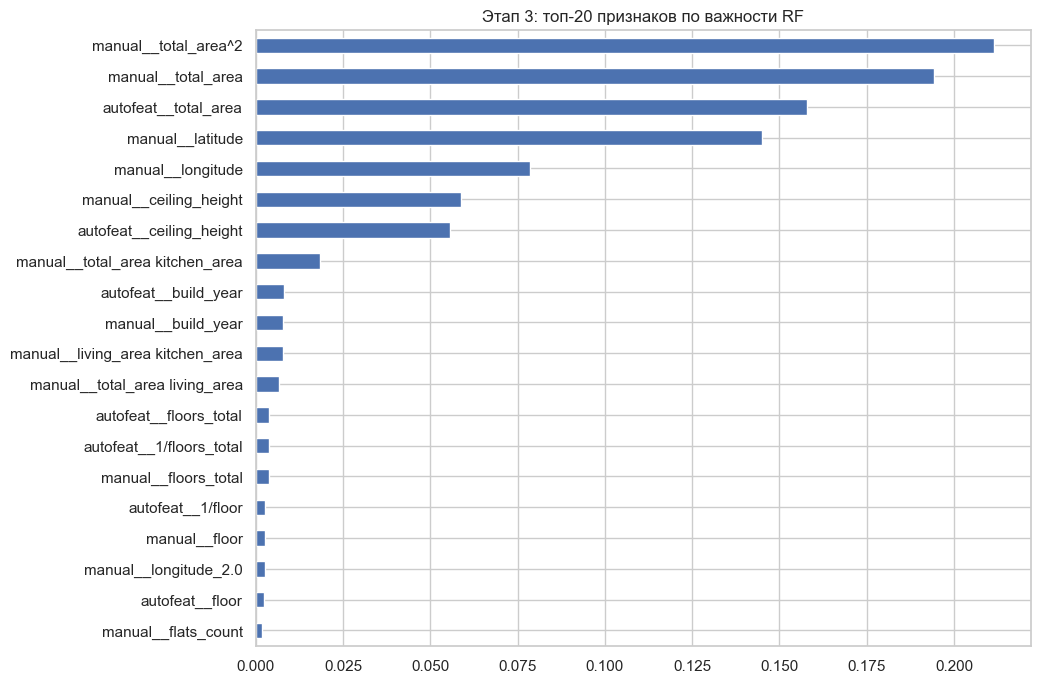

In [11]:
# Примеры сгенерированных признаков и важности для анализа результата.
manual_preview = manual_transformer.transform(X_train.head(5))
display(manual_preview.filter(regex="\^2| "))
display(pd.DataFrame(X_train_transformed[:5, -len(auto_transformer.all_columns_):],
                     columns=auto_transformer.all_columns_).iloc[:, -min(5, len(auto_transformer.all_columns_)):])

pd.DataFrame({"feature": feature_names}).to_csv(ARTIFACTS_DIR / "stage3_feature_names.csv", index=False)
importance3 = pd.Series(stage3_estimator.feature_importances_, index=feature_names).sort_values(ascending=False)
importance3.to_csv(ARTIFACTS_DIR / "stage3_feature_importance.csv", header=["importance"])
fig, ax = plt.subplots(figsize=(10, 8))
importance3.head(20).sort_values().plot.barh(ax=ax)
ax.set_title("Этап 3: топ-20 признаков по важности RF")
fig.savefig(ARTIFACTS_DIR / "stage3_feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()

autofeat добавил в модель стандартные нелинейные преобразования исходных признаков: обратные величины, логарифмы, квадратные корни и квадраты. Все преобразования зашиты в sklearn.Pipeline, поэтому обучение и предсказание выполняются единообразно.

In [12]:
# Логируем параметры, скорость, метрики, код, графики и полный Pipeline в Model Registry.
input_example = X_train.head(3)
signature3 = infer_signature(input_example, stage3_pipeline.predict(input_example))
with mlflow.start_run(run_name="stage3_feature_generation") as run3:
    mlflow.set_tags({"stage": "3", "feature_engineering": "polynomial_bins_autofeat"})
    mlflow.log_params({"n_estimators": N_ESTIMATORS, "max_depth": 12, "polynomial_degree": 2,
                       "bins": 5, "autofeat_steps": 1, "autofeat_featsel_runs": 3})
    mlflow.log_params({"input_features": X_train.shape[1], "generated_features": X_train_transformed.shape[1],
                       "autofeat_new_features": len(auto_transformer.new_feat_cols_)})
    mlflow.log_metrics(stage3_metrics)
    mlflow.log_metrics({"fit_seconds": feature_fit_seconds + model_fit_seconds,
                        "predict_seconds": stage3_predict_seconds})
    for filename in ["stage3_feature_names.csv", "stage3_feature_importance.csv", "stage3_feature_importance.png"]:
        mlflow.log_artifact(str(ARTIFACTS_DIR / filename), artifact_path="features")
    mlflow.log_artifact(str(NOTEBOOK_PATH), artifact_path="code")
    log_environment()
    mlflow.sklearn.log_model(stage3_pipeline, artifact_path="model", signature=signature3,
                             input_example=input_example, registered_model_name=MODEL_NAME)
    print("Stage 3 run id:", run3.info.run_id)

C:\Users\Natrogona\Documents\Магистратура\MlOps_baseline_project\MlOps_baseline\.venv\Lib\site-packages\mlflow\types\utils.py:393: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(


2026/11/21 16:35:21 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


Registered model 'real_estate_price_model' already exists. Creating a new version of this model...
2026/11/21 16:35:21 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: real_estate_price_model, version 2


Stage 3 run id: ddec83c4d476458197e4a35cea662ff4


Created version '2' of model 'real_estate_price_model'.


## Этап 4. Отбор признаков

In [ ]:
# Берём топ-25 признаков по важности из модели этапа 3. Важность считалась только на train, поэтому test в отборе не участвует и утечки данных нет.
candidate_positions = np.argsort(stage3_estimator.feature_importances_)[-CANDIDATE_COUNT:]
candidate_names = [feature_names[i] for i in candidate_positions]
selection_rng = np.random.default_rng(RANDOM_STATE)
selection_indices = selection_rng.choice(
    len(X_train), size=min(SELECTION_SAMPLE_SIZE, len(X_train)), replace=False,
)
X_selection = X_train_transformed[selection_indices][:, candidate_positions]
y_selection = y_train.iloc[selection_indices]


def selection_estimator():
    # Небольшой RF делает последовательный поиск воспроизводимым и не слишком дорогим.
    return RandomForestRegressor(n_estimators=20, max_depth=10, random_state=RANDOM_STATE, n_jobs=1)


sfs_forward = SequentialFeatureSelector(
    selection_estimator(), k_features=SELECTED_COUNT, forward=True, floating=False,
    scoring="neg_root_mean_squared_error", cv=2, n_jobs=-1,
)
sfs_backward = SequentialFeatureSelector(
    selection_estimator(), k_features=SELECTED_COUNT, forward=False, floating=False,
    scoring="neg_root_mean_squared_error", cv=2, n_jobs=-1,
)
print("Forward selection...")
sfs_forward.fit(X_selection, y_selection)
print("Backward selection...")
sfs_backward.fit(X_selection, y_selection)

forward_names = [candidate_names[i] for i in sfs_forward.k_feature_idx_]
backward_names = [candidate_names[i] for i in sfs_backward.k_feature_idx_]
print("Forward:", forward_names)
print("Backward:", backward_names)

Forward selection...


Backward selection...


Forward: ['autofeat__floor', 'manual__longitude_2.0', 'manual__floors_total', 'autofeat__1/floors_total', 'manual__total_area living_area', 'manual__build_year', 'manual__longitude', 'manual__latitude', 'autofeat__total_area', 'manual__total_area^2']
Backward: ['autofeat__flats_count', 'manual__has_elevator', 'autofeat__1/floor', 'autofeat__1/floors_total', 'manual__total_area living_area', 'manual__build_year', 'manual__longitude', 'manual__latitude', 'autofeat__total_area', 'manual__total_area^2']


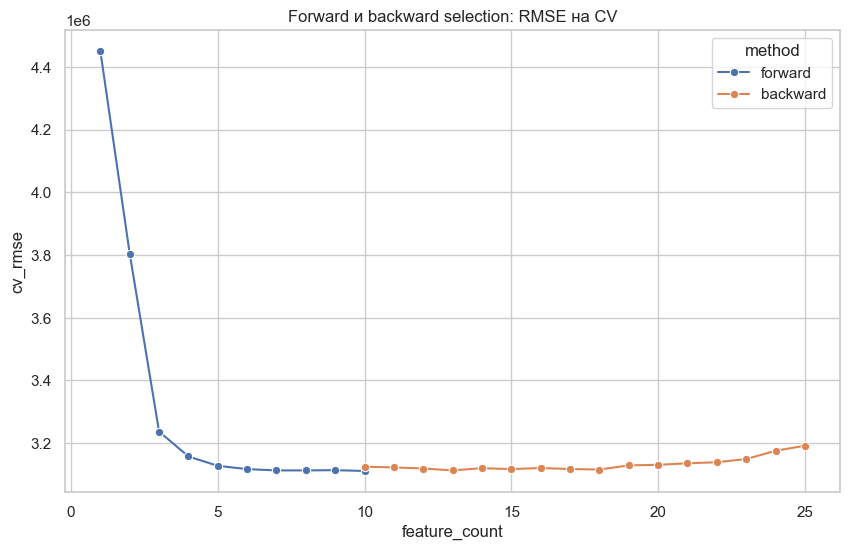

Пересечение: ['autofeat__1/floors_total', 'manual__total_area living_area', 'manual__build_year', 'manual__longitude', 'manual__latitude', 'autofeat__total_area', 'manual__total_area^2']
Итоговые признаки: ['autofeat__1/floors_total', 'manual__total_area living_area', 'manual__build_year', 'manual__longitude', 'manual__latitude', 'autofeat__total_area', 'manual__total_area^2', 'manual__floors_total', 'autofeat__1/floor', 'manual__longitude_2.0']


In [14]:
# Сравниваем траектории качества и формируем итоговый список без обращения к test.
selection_history = []
for method, selector in [("forward", sfs_forward), ("backward", sfs_backward)]:
    for subset in selector.subsets_.values():
        selection_history.append({"method": method, "feature_count": len(subset["feature_idx"]),
                                  "cv_rmse": -subset["avg_score"],
                                  "features": ", ".join(candidate_names[i] for i in subset["feature_idx"])})
selection_history_df = pd.DataFrame(selection_history)
selection_history_df.to_csv(ARTIFACTS_DIR / "stage4_selection_history.csv", index=False)

fig, ax = plt.subplots(figsize=(10, 6))
sns.lineplot(data=selection_history_df, x="feature_count", y="cv_rmse", hue="method", marker="o", ax=ax)
ax.set_title("Forward и backward selection: RMSE на CV")
fig.savefig(ARTIFACTS_DIR / "stage4_selection_cv.png", dpi=150, bbox_inches="tight")
plt.show()

common = [name for name in forward_names if name in backward_names]
union = list(dict.fromkeys(forward_names + backward_names))
remaining = sorted((name for name in union if name not in common),
                   key=lambda name: importance3[name], reverse=True)
selected_names = (common + remaining)[:SELECTED_COUNT]
selected_positions = [feature_names.index(name) for name in selected_names]
print("Пересечение:", common)
print("Итоговые признаки:", selected_names)

for filename, names in [("stage4_forward_features.txt", forward_names),
                        ("stage4_backward_features.txt", backward_names),
                        ("stage4_selected_features.txt", selected_names)]:
    (ARTIFACTS_DIR / filename).write_text("\n".join(names), encoding="utf-8")

Отбор выполнен в два шага. Сначала RandomForest отранжировал все сгенерированные признаки по важности, в дальнейшую работу вошли 25 лучших. 
Затем на случайной train-подвыборке независимо запустили два метода из mlxtend: Forward Selection (последовательное добавление) и Backward Selection (последовательное удаление). Оба работали с 2-fold CV по RMSE. 

Итоговый список собираем так: сначала берётся пересечение методов, а затем наиболее важные признаки из объединения до нужного размера. Test-выборка в отборе не участвовала, она осталась только для финальной оценки.

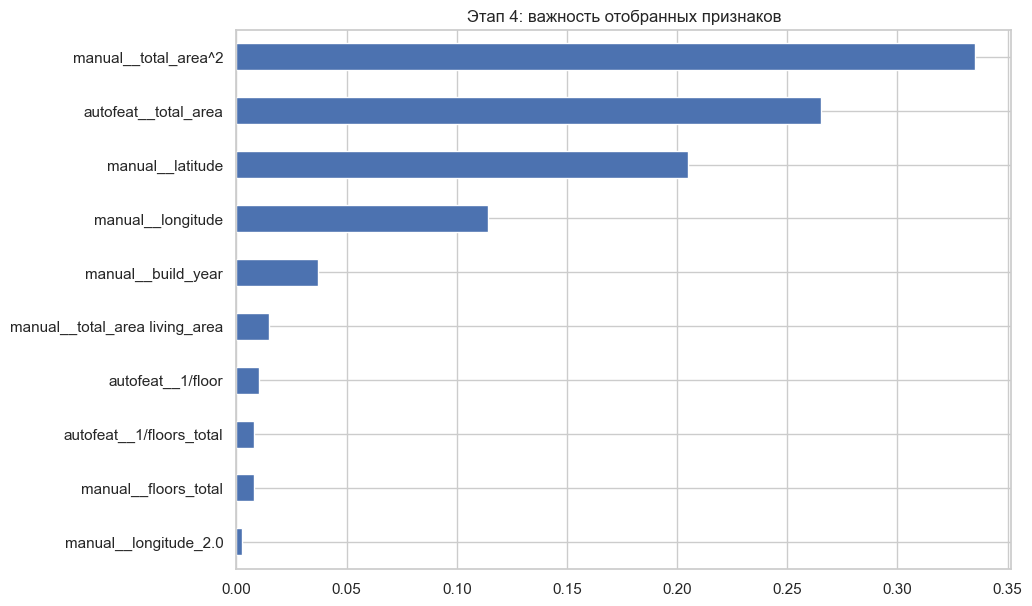

{
  "mae": 2016018.197569707,
  "rmse": 2753191.9858506247,
  "r2": 0.7696209217406804
}


In [15]:
# Обучаем RF на полном train только с отобранными признаками; параметры пока прежние.
selector = ColumnTransformer([("selected", "passthrough", selected_positions)])
selector.fit(X_train_transformed)
stage4_estimator = RandomForestRegressor(
    n_estimators=N_ESTIMATORS, max_depth=12, random_state=RANDOM_STATE, n_jobs=-1,
)
fit_started = time.perf_counter()
stage4_estimator.fit(X_train_transformed[:, selected_positions], y_train)
stage4_fit_seconds = time.perf_counter() - fit_started
predict_started = time.perf_counter()
stage4_predictions = stage4_estimator.predict(X_test_transformed[:, selected_positions])
stage4_predict_seconds = time.perf_counter() - predict_started
stage4_metrics = regression_metrics(y_test, stage4_predictions)
stage4_pipeline = Pipeline([("features", feature_union), ("selector", selector), ("model", stage4_estimator)])

importance4 = pd.Series(stage4_estimator.feature_importances_, index=selected_names).sort_values(ascending=False)
importance4.to_csv(ARTIFACTS_DIR / "stage4_feature_importance.csv", header=["importance"])
fig, ax = plt.subplots(figsize=(10, 7))
importance4.sort_values().plot.barh(ax=ax)
ax.set_title("Этап 4: важность отобранных признаков")
fig.savefig(ARTIFACTS_DIR / "stage4_feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()
print(json.dumps(stage4_metrics, indent=2))

После отбора метрики немного просели (RMSE 2 753 192 против 2 720 082 на этапе 3). Возможно, при отборе признаков мы потеряли часть полезных сочетаний. 
Для выполнения задания зафиксируем этот результат в MLflow как версия 3 модели.

Далее попробуем улучшить результаты модели через подбор гиперпараметров. 

In [16]:
# Регистрируем третью версию модели и все доказательства процесса отбора.
signature4 = infer_signature(input_example, stage4_pipeline.predict(input_example))
with mlflow.start_run(run_name="stage4_feature_selection") as run4:
    mlflow.set_tags({"stage": "4", "selection_methods": "forward_backward_mlxtend"})
    mlflow.log_params({"n_estimators": N_ESTIMATORS, "max_depth": 12,
                       "candidate_count": len(candidate_names), "selected_count": len(selected_names),
                       "selection_sample_size": len(X_selection), "selection_cv": 2})
    mlflow.log_metrics(stage4_metrics)
    mlflow.log_metrics({"fit_seconds": stage4_fit_seconds, "predict_seconds": stage4_predict_seconds,
                        "forward_best_cv_rmse": -sfs_forward.k_score_,
                        "backward_best_cv_rmse": -sfs_backward.k_score_})
    for filename in ["stage4_selection_history.csv", "stage4_selection_cv.png",
                     "stage4_forward_features.txt", "stage4_backward_features.txt",
                     "stage4_selected_features.txt", "stage4_feature_importance.csv",
                     "stage4_feature_importance.png"]:
        mlflow.log_artifact(str(ARTIFACTS_DIR / filename), artifact_path="selection")
    mlflow.log_artifact(str(NOTEBOOK_PATH), artifact_path="code")
    log_environment()
    mlflow.sklearn.log_model(stage4_pipeline, artifact_path="model", signature=signature4,
                             input_example=input_example, registered_model_name=MODEL_NAME)
    print("Stage 4 run id:", run4.info.run_id)

C:\Users\Natrogona\Documents\Магистратура\MlOps_baseline_project\MlOps_baseline\.venv\Lib\site-packages\mlflow\types\utils.py:393: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(


C:\Users\Natrogona\Documents\Магистратура\MlOps_baseline_project\MlOps_baseline\.venv\Lib\site-packages\_distutils_hack\__init__.py:33: UserWarning: Setuptools is replacing distutils.
  warnings.warn("Setuptools is replacing distutils.")
2026/11/21 16:36:25 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


Registered model 'real_estate_price_model' already exists. Creating a new version of this model...
2026/11/21 16:36:25 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: real_estate_price_model, version 3


Stage 4 run id: 89eb938705544496b7795146e4436daa


Created version '3' of model 'real_estate_price_model'.


## Этап 5. Подбор гиперпараметров и финальная модель

Подбор гиперпараметров выполним через оптуну и вторым другим методом. 

[I 2026-11-21 16:36:25,949] A new study created in memory with name: no-name-68cb4619-d171-469f-9c53-22b970321e03


C:\Users\Natrogona\AppData\Local\Temp\ipykernel_29192\4078971938.py:27: ExperimentalWarning: MLflowCallback is experimental (supported from v1.4.0). The interface can change in the future.
  callback = MLflowCallback(


[I 2026-11-21 16:36:27,682] Trial 0 finished with value: 2945784.781920913 and parameters: {'n_estimators': 100, 'max_depth': 24, 'min_samples_leaf': 4, 'max_features': 'sqrt'}. Best is trial 0 with value: 2945784.781920913.


[I 2026-11-21 16:36:30,354] Trial 1 finished with value: 2889707.1313477005 and parameters: {'n_estimators': 50, 'max_depth': 24, 'min_samples_leaf': 4, 'max_features': 1.0}. Best is trial 1 with value: 2889707.1313477005.


[I 2026-11-21 16:36:38,606] Trial 2 finished with value: 2921839.243875142 and parameters: {'n_estimators': 200, 'max_depth': 12, 'min_samples_leaf': 1, 'max_features': 1.0}. Best is trial 1 with value: 2889707.1313477005.


[I 2026-11-21 16:36:42,471] Trial 3 finished with value: 2920851.465750935 and parameters: {'n_estimators': 100, 'max_depth': 12, 'min_samples_leaf': 4, 'max_features': 1.0}. Best is trial 1 with value: 2889707.1313477005.


... (13 outputs left out)

[I 2026-11-21 16:38:04,105] Trial 17 finished with value: 2937988.3712546416 and parameters: {'n_estimators': 200, 'max_depth': 16, 'min_samples_leaf': 3, 'max_features': 'sqrt'}. Best is trial 10 with value: 2871279.5816739337.


[I 2026-11-21 16:38:10,415] Trial 18 finished with value: 2873732.2554298695 and parameters: {'n_estimators': 150, 'max_depth': 20, 'min_samples_leaf': 2, 'max_features': 0.7}. Best is trial 10 with value: 2871279.5816739337.


[I 2026-11-21 16:38:16,026] Trial 19 finished with value: 2922618.160182254 and parameters: {'n_estimators': 200, 'max_depth': 12, 'min_samples_leaf': 2, 'max_features': 0.7}. Best is trial 10 with value: 2871279.5816739337.


Optuna parent run id: dc576f0850f6459f947e1a23645c3b68


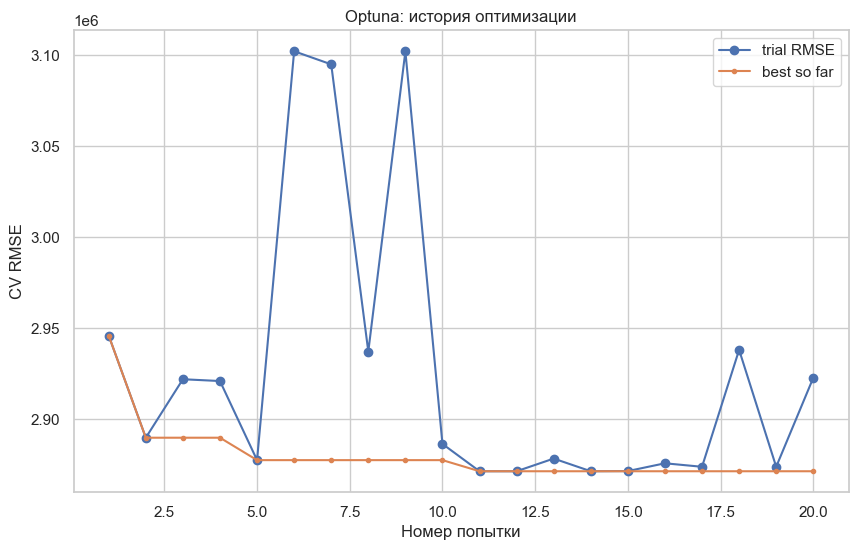

Optuna best: {'n_estimators': 200, 'max_depth': 20, 'min_samples_leaf': 2, 'max_features': 0.7} RMSE: 2871279.5816739337


In [ ]:
search_rng = np.random.default_rng(RANDOM_STATE)
search_indices = search_rng.choice(len(X_train), size=min(SEARCH_SAMPLE_SIZE, len(X_train)), replace=False)
X_search = X_train_transformed[search_indices][:, selected_positions]
y_search = y_train.iloc[search_indices]
cv = KFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)


def optuna_objective(trial):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 50, 200, step=50),
        "max_depth": trial.suggest_int("max_depth", 8, 24, step=4),
        "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 5),
        "max_features": trial.suggest_categorical("max_features", ["sqrt", 0.7, 1.0]),
    }
    estimator = RandomForestRegressor(**params, random_state=RANDOM_STATE, n_jobs=-1)
    scores = cross_val_score(estimator, X_search, y_search, scoring="neg_root_mean_squared_error",
                             cv=cv, n_jobs=1)
    trial.set_user_attr("cv_rmse_std", float(scores.std()))
    return float(-scores.mean())


study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
with mlflow.start_run(run_name="stage5_optuna_parent") as optuna_parent:
    mlflow.set_tags({"stage": "5", "optimization": "optuna_tpe"})
    mlflow.log_params({"n_trials": N_TRIALS, "search_rows": len(X_search), "cv_folds": 3})
    callback = MLflowCallback(
        tracking_uri=mlflow.get_tracking_uri(), metric_name="cv_rmse",
        create_experiment=False, mlflow_kwargs={"nested": True},
    )
    study.optimize(optuna_objective, n_trials=N_TRIALS, callbacks=[callback], show_progress_bar=False)
    mlflow.log_params({f"best_{key}": value for key, value in study.best_params.items()})
    mlflow.log_metric("best_cv_rmse", study.best_value)
    study.trials_dataframe().to_csv(ARTIFACTS_DIR / "stage5_optuna_trials.csv", index=False)
    log_environment()
    print("Optuna parent run id:", optuna_parent.info.run_id)

fig, ax = plt.subplots(figsize=(10, 6))
values = [trial.value for trial in study.trials if trial.value is not None]
ax.plot(range(1, len(values) + 1), values, marker="o", label="trial RMSE")
ax.plot(range(1, len(values) + 1), np.minimum.accumulate(values), marker=".", label="best so far")
ax.set(xlabel="Номер попытки", ylabel="CV RMSE", title="Optuna: история оптимизации")
ax.legend()
fig.savefig(ARTIFACTS_DIR / "stage5_optuna_history.png", dpi=150, bbox_inches="tight")
plt.show()
print("Optuna best:", study.best_params, "RMSE:", study.best_value)

Оптуна за 20 попыток перебрала разные комбинации: на каждой сэмплер TPE выбирает новый набор гиперпараметров из заданных распределений, обучает модель, считает CV RMSE и запоминает результат. Лучший набор выбирается автоматически по истории попыток. Отдельные попытки дают RMSE до 3.10 млн, но лучший результат (best so far) улучшается монотонно и к ~10–11 попытке выходит на плато около 2.87 млн, что, в целом, лучше бэйзлайна. 

Вторым методом попробуем RandomizedSearchCV как простой и воспроизводимый инструмент из стандартной библиотеке sklearn. 

In [ ]:
param_distributions = {
    "n_estimators": [50, 100, 150, 200],
    "max_depth": [8, 12, 16, 20, 24],
    "min_samples_leaf": [1, 2, 3, 4, 5],
    "max_features": ["sqrt", 0.7, 1.0],
}
random_search = RandomizedSearchCV(
    RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=1),
    param_distributions=param_distributions, n_iter=N_ITER, scoring="neg_root_mean_squared_error",
    cv=cv, random_state=RANDOM_STATE, n_jobs=-1, return_train_score=False,
)
with mlflow.start_run(run_name="stage5_random_search_parent") as random_parent:
    mlflow.set_tags({"stage": "5", "optimization": "randomized_search_cv"})
    mlflow.log_params({"n_iter": N_ITER, "search_rows": len(X_search), "cv_folds": 3})
    random_search.fit(X_search, y_search)
    results = random_search.cv_results_
    for i, params in enumerate(results["params"]):
        with mlflow.start_run(run_name=f"random_search_trial_{i + 1}", nested=True):
            mlflow.log_params(params)
            mlflow.log_metrics({
                "cv_rmse": float(-results["mean_test_score"][i]),
                "cv_rmse_std": float(results["std_test_score"][i]),
                "rank": int(results["rank_test_score"][i]),
            })
    mlflow.log_params({f"best_{key}": value for key, value in random_search.best_params_.items()})
    mlflow.log_metric("best_cv_rmse", float(-random_search.best_score_))
    pd.DataFrame(results).drop(columns=["params"]).to_csv(ARTIFACTS_DIR / "stage5_random_search_results.csv", index=False)
    log_environment()
    print("Random Search parent run id:", random_parent.info.run_id)

random_rmse = float(-random_search.best_score_)
print("Random Search best:", random_search.best_params_, "RMSE:", random_rmse)

Random Search parent run id: 11747f1be8ed4bd4afc1e3068b15b7fe
Random Search best: {'n_estimators': 200, 'min_samples_leaf': 1, 'max_features': 0.7, 'max_depth': 20} RMSE: 2871950.4115284258


RandomizedSearchCV случайно выбрал 15 комбинаций гиперпараметров из тех же распределений, что и Optuna, и оценил каждую по 3-fold CV. Каждая комбинация сохранена отдельным вложенным MLflow run с метриками cv_rmse, cv_rmse_std и рангом, вся таблица результатов дополнительно лежит в артефактах как stage5_random_search_results.csv. Лучший набор случайного перебора: n_estimators=200, max_depth=20, min_samples_leaf=1, max_features=0.7, CV RMSE = 2 871 950. Примечательно, что он почти совпадает с лучшим набором Optuna, однако по CV RMSE случайный перебор чуть уступил оптуне, поэтому финальную модель будем обучать на параметрах, подобранных оптуной, но для пайплайна напишем код, который автоматически будет выбирать лучшие параметры. 

In [ ]:
tuning_comparison = {
    "optuna": {"cv_rmse": float(study.best_value), "params": study.best_params},
    "random_search": {"cv_rmse": random_rmse, "params": random_search.best_params_},
}
if study.best_value <= random_rmse:
    best_method = "optuna"
    best_params = dict(study.best_params)
else:
    best_method = "random_search"
    best_params = dict(random_search.best_params_)
tuning_comparison["selected_method"] = best_method
tuning_comparison["selected_params"] = best_params
save_json(tuning_comparison, ARTIFACTS_DIR / "stage5_tuning_comparison.json")
print("Выбран метод:", best_method)
print("Лучшие параметры:", best_params)

Выбран метод: optuna
Лучшие параметры: {'n_estimators': 200, 'max_depth': 20, 'min_samples_leaf': 2, 'max_features': 0.7}


,mae,rmse,r2,rmse_improvement_vs_baseline_pct,r2_gain_vs_baseline
stage,,,,,
1_baseline,2.003737e+06,2.721366e+06,0.774916,0.000000,0.000000
3_generated_features,2.006002e+06,2.720082e+06,0.775129,0.047172,0.000212
4_selected_features,2.016018e+06,2.753192e+06,0.769621,-1.169494,-0.005295
5_tuned_model,1.778240e+06,2.477366e+06,0.813469,8.966070,0.038553


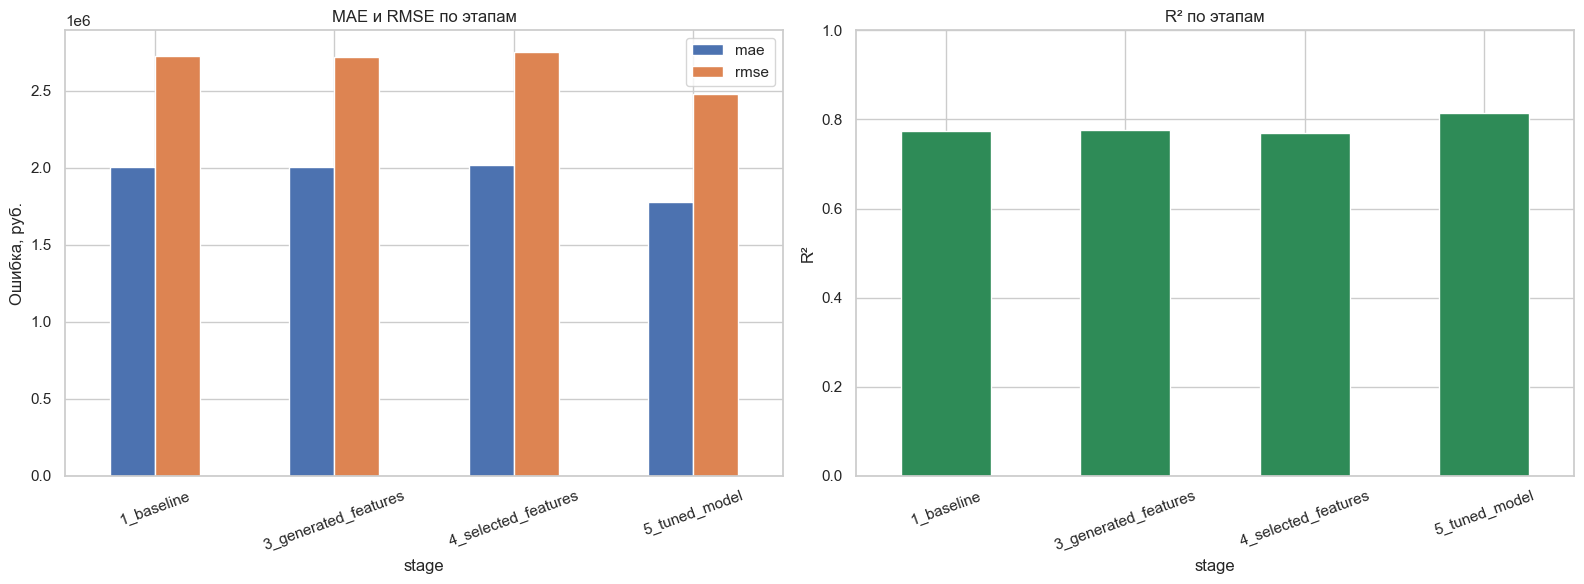

In [20]:
# Финальное обучение: полный train, отобранные признаки, лучшие гиперпараметры.
final_estimator = RandomForestRegressor(**best_params, random_state=RANDOM_STATE, n_jobs=-1)
fit_started = time.perf_counter()
final_estimator.fit(X_train_transformed[:, selected_positions], y_train)
final_fit_seconds = time.perf_counter() - fit_started
predict_started = time.perf_counter()
final_predictions = final_estimator.predict(X_test_transformed[:, selected_positions])
final_predict_seconds = time.perf_counter() - predict_started
final_metrics = regression_metrics(y_test, final_predictions)
final_pipeline = Pipeline([("features", feature_union), ("selector", selector), ("model", final_estimator)])

comparison = pd.DataFrame([
    {"stage": "1_baseline", **baseline_metrics},
    {"stage": "3_generated_features", **stage3_metrics},
    {"stage": "4_selected_features", **stage4_metrics},
    {"stage": "5_tuned_model", **final_metrics},
]).set_index("stage")
comparison["rmse_improvement_vs_baseline_pct"] = 100 * (baseline_metrics["rmse"] - comparison["rmse"]) / baseline_metrics["rmse"]
comparison["r2_gain_vs_baseline"] = comparison["r2"] - baseline_metrics["r2"]
display(comparison)
comparison.to_csv(ARTIFACTS_DIR / "final_model_comparison.csv")
save_json(comparison.reset_index().to_dict(orient="records"), ARTIFACTS_DIR / "final_model_comparison.json")

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
comparison[["mae", "rmse"]].plot.bar(ax=axes[0])
axes[0].set(title="MAE и RMSE по этапам", ylabel="Ошибка, руб.")
axes[0].tick_params(axis="x", rotation=20)
comparison["r2"].plot.bar(ax=axes[1], color="seagreen")
axes[1].set(title="R² по этапам", ylabel="R²", ylim=(0, 1))
axes[1].tick_params(axis="x", rotation=20)
plt.tight_layout()
fig.savefig(ARTIFACTS_DIR / "final_metrics_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

Обучили финальную модель и сравнили метрики всех четырёх версий: baseline, модель со сгенерированными признаками, модель с отобранными признаками и модель с подобранными гиперпараметрами. Первые три идут почти вровень: RMSE в районе 2,72–2,75 млн, R² около 0,77. Основной прирост дала именно настройка гиперпараметров: RMSE снизился с 2,72 млн до 2,48 млн, R² вырос до 0,8135. Работа с признаками на этом датасете дала небольшие колебания в пределах погрешности, а вот подобор гиперпараметров к RandomForest дает почти 9% RMSE.

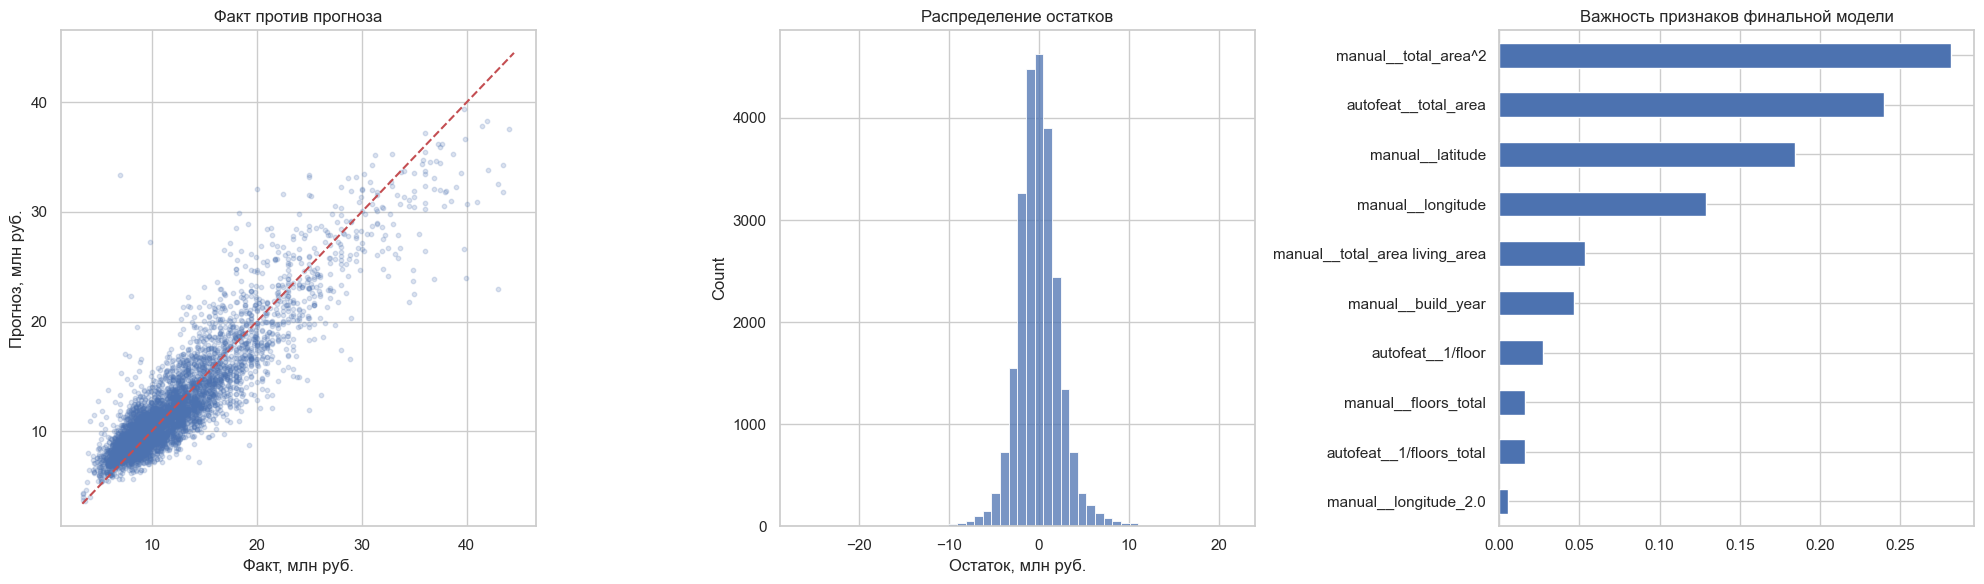

{
  "mae": 1778240.377379594,
  "rmse": 2477366.220683011,
  "r2": 0.8134692372373338
}


In [ ]:
final_importance = pd.Series(final_estimator.feature_importances_, index=selected_names).sort_values(ascending=False)
final_importance.to_csv(ARTIFACTS_DIR / "final_feature_importance.csv", header=["importance"])
residuals = y_test.to_numpy() - final_predictions
residual_sample = np.random.default_rng(RANDOM_STATE).choice(len(y_test), size=min(5_000, len(y_test)), replace=False)

fig, axes = plt.subplots(1, 3, figsize=(20, 6))
axes[0].scatter(y_test.to_numpy()[residual_sample] / 1e6, final_predictions[residual_sample] / 1e6, alpha=0.2, s=10)
axes[0].plot([df["price"].min() / 1e6, df["price"].max() / 1e6],
             [df["price"].min() / 1e6, df["price"].max() / 1e6], "r--")
axes[0].set(xlabel="Факт, млн руб.", ylabel="Прогноз, млн руб.", title="Факт против прогноза")
sns.histplot(residuals / 1e6, bins=50, ax=axes[1])
axes[1].set(xlabel="Остаток, млн руб.", title="Распределение остатков")
final_importance.sort_values().plot.barh(ax=axes[2])
axes[2].set_title("Важность признаков финальной модели")
plt.tight_layout()
fig.savefig(ARTIFACTS_DIR / "final_diagnostics.png", dpi=150, bbox_inches="tight")
plt.show()
print(json.dumps(final_metrics, ensure_ascii=False, indent=2))

После обучения выполнили дополнительную "диагностику", чтобы посмотреть, где модель ошибается и на что опирается в своих прогнозах. По первому графику видно, что в диапазоне до ~20 млн точки ложатся вдоль диагонали, а дорогие объекты модель систематически недооценивает. Распределение остатков сосредоточено около нуля, что может означать, в среднем модель не завышает и не занижает цену. По важности лидируют площадь и география, что, в целом, совпадает с выводами, сделанными нами ранее в блоке с EDA. 

In [ ]:
# Финальный ран с полным пайплайном, сигнатурой, метриками, параметрами и прочими доп. артефактами
final_signature = infer_signature(input_example, final_pipeline.predict(input_example))
with mlflow.start_run(run_name="stage5_final_model") as final_run:
    mlflow.set_tags({"stage": "5", "model_type": "final", "optimization_method": best_method})
    mlflow.log_params(best_params)
    mlflow.log_params({"selected_method": best_method, "selected_features_count": len(selected_names),
                       "train_rows": len(X_train), "test_rows": len(X_test)})
    mlflow.log_metrics(final_metrics)
    mlflow.log_metrics({"fit_seconds": final_fit_seconds, "predict_seconds": final_predict_seconds,
                        "best_cv_rmse": tuning_comparison[best_method]["cv_rmse"],
                        "rmse_improvement_pct": comparison.loc["5_tuned_model", "rmse_improvement_vs_baseline_pct"]})
    mlflow.log_artifact(str(ARTIFACTS_DIR / "stage5_optuna_trials.csv"), artifact_path="tuning")
    mlflow.log_artifact(str(ARTIFACTS_DIR / "stage5_optuna_history.png"), artifact_path="tuning")
    mlflow.log_artifact(str(ARTIFACTS_DIR / "stage5_random_search_results.csv"), artifact_path="tuning")
    mlflow.log_artifact(str(ARTIFACTS_DIR / "stage5_tuning_comparison.json"), artifact_path="tuning")
    mlflow.log_artifact(str(ARTIFACTS_DIR / "final_model_comparison.csv"), artifact_path="evaluation")
    mlflow.log_artifact(str(ARTIFACTS_DIR / "final_metrics_comparison.png"), artifact_path="evaluation")
    mlflow.log_artifact(str(ARTIFACTS_DIR / "final_diagnostics.png"), artifact_path="evaluation")
    mlflow.log_artifact(str(ARTIFACTS_DIR / "final_feature_importance.csv"), artifact_path="evaluation")
    mlflow.log_artifact(str(NOTEBOOK_PATH), artifact_path="code")
    log_environment()
    mlflow.sklearn.log_model(final_pipeline, artifact_path="model", signature=final_signature,
                             input_example=input_example, registered_model_name=MODEL_NAME)
    save_json({"run_id": final_run.info.run_id, "experiment_id": experiment.experiment_id,
               "model_name": MODEL_NAME, "metrics": final_metrics,
               "best_method": best_method, "best_params": best_params},
              ARTIFACTS_DIR / "final_run_info.json")
    print("Final run id:", final_run.info.run_id)

print("Готово: зарегистрированы baseline и три улучшенные версии модели.")

C:\Users\Natrogona\Documents\Магистратура\MlOps_baseline_project\MlOps_baseline\.venv\Lib\site-packages\mlflow\types\utils.py:393: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(


C:\Users\Natrogona\Documents\Магистратура\MlOps_baseline_project\MlOps_baseline\.venv\Lib\site-packages\_distutils_hack\__init__.py:33: UserWarning: Setuptools is replacing distutils.
  warnings.warn("Setuptools is replacing distutils.")
2026/11/21 16:40:04 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


Registered model 'real_estate_price_model' already exists. Creating a new version of this model...
2026/11/21 16:40:07 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: real_estate_price_model, version 4


Final run id: 4f224f23fa914f18b2da0eb2d13dbc93
Готово: зарегистрированы baseline и три улучшенные версии модели.


Created version '4' of model 'real_estate_price_model'.


Финальная модель сохранена в MLflow запуском stage5_final_model: залогированы метрики на test, лучшие гиперпараметры, скорость обучения и предсказания, а также улучшение RMSE в процентах относительно baseline. 
Артефакты разложены по папкам: tuning (результаты Optuna и Random Search, сравнение методов), evaluation (сравнение всех версий, диагностика, важность признаков) и code (сам ноутбук), а также зафиксировано окружение. 
Модель залогирована со сигнатурой и примером входа и зарегистрирована в Model Registry как версия 4 real_estate_price_model. Все четыре версии теперь лежат в реестре: если вернуться к проекту позже, нужную модель можно загрузить одной строкой models:/real_estate_price_model/4 и сразу получить готовый пайплайн со всей предобработкой внутри.

## Итоговый вывод

По итогам проекта мы прошли полный цикл работы с моделью: развернули MLflow Tracking Server и Model Registry с PostgreSQL и S3, зарегистрировали baseline, провели EDA и поняли, что главные драйверы цены в данном случае это площадь и география.  Помимо этого мы сгенерировали новые признаки, отобрали их и подобрали гиперпараметры двумя независимыми методами. 

Каждый шаг при этом сопровождался метриками, графиками и артефактами в MLflow, включая те этапы, где улучшения не получилось. 

В результате работы по улучшению модели RMSE снизился с 2,72 млн до 2,48 млн (на 8,97%), а R² вырос до 0,8135. 

Главная практическая ценность этого проекта заключается в воспроизводимости (потому что подобный Ml-цикл мы, в целом, проходили на более ранних дисциплинах): все четыре версии модели лежат в Model Registry под одним именем, лучшую можно загрузить одной строкой и сразу получить готовый пайплайн с полной предобработкой внутри. По MLflow при этом восстанавливается вся история экспериментов: параметры, метрики, признаки, окружение. Это позволяет вернуться к проекту в любой момент и продолжить с того места, где остановились. Например, данные могут измениться (дрейф данных) и нам придётся плотнее поработать с признаками - тогда мы сможем безболезненно переобучить финальную модель и обновить её в проде.
